# 03 Joint objective: building blocks and unit-test evidence

**Goal:** show that each piece of `L = L_wCE + lambda_f L_fair + lambda_c L_cal + lambda_a L_adv` behaves as specified (GRL, soft fairness, soft calibration, warm-up/ramp, lambda = 0 equals A2).
No model is trained here beyond tiny demos; joint training runs start in Phase 4.

In [1]:
import json, subprocess, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from src.utils import load_config, resolve, seed_everything
from src.losses.grl import grad_reverse
from src.losses.fairness import fairness_loss
from src.losses.calibration import soft_group_ece
from src.losses.joint import JointConfig, JointLoss
from src.losses.weighted_ce import weighted_bce
from src.models.heads import JointModel
from src.models.nets import build_model
from src.eval.metrics import ece_equal_freq, compute_metrics
from src.data.tensors import load_arrays

cfg = load_config('configs/train.yaml'); seed_everything(0)
W = json.loads((resolve(cfg['paths']['prep_artifacts']) / 'class_weights.json').read_text())
print('class weights', {k: round(v, 3) for k, v in W.items()})

class weights {'0': 0.544, '1': 6.194}


## 1. Gradient reversal: identity forward, gradient x (-lambda) backward

In [2]:
rows = []
for lam in [0.0, 0.5, 1.0, 2.0]:
    x = torch.randn(64, 5, requires_grad=True); w = torch.randn(64, 5)
    out = grad_reverse(x, lam); (out * w).sum().backward()
    rows.append({'lambda': lam, 'forward identical': bool(torch.equal(out, x)),
                 'max |grad + lambda*w|': float((x.grad + lam * w).abs().max())})
pd.DataFrame(rows).set_index('lambda')

,forward identical,max |grad + lambda*w|
lambda,,
0.0,True,0.0
0.5,True,0.0
1.0,True,0.0
2.0,True,0.0


## 2. Warm-up and lambda ramp (3 warm-up epochs, then linear over 5)

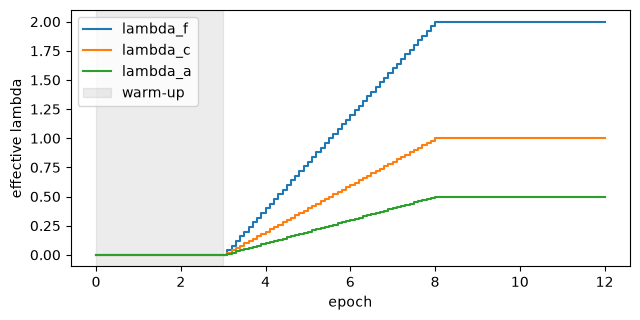

In [3]:
jc = JointConfig.from_config(cfg, lambda_f=2.0, lambda_c=1.0, lambda_a=0.5)
loss = JointLoss(jc, W['0'], W['1']); eps = np.linspace(0, 12, 121); lam = []
for e in eps: loss.set_epoch(e); lam.append(loss.lambdas())
lam = pd.DataFrame(lam, index=eps)
ax = lam.plot(figsize=(6.5, 3.3), drawstyle='steps-post')
ax.axvspan(0, 3, color='grey', alpha=0.15, label='warm-up'); ax.set_xlabel('epoch'); ax.set_ylabel('effective lambda')
ax.legend(['lambda_f', 'lambda_c', 'lambda_a', 'warm-up']); plt.tight_layout(); plt.show()

## 3. Soft fairness loss tracks the hard flag-rate / equalized-odds gaps

In [4]:
g = torch.Generator().manual_seed(1); n = 40000
y = (torch.rand(n, generator=g) < 0.2).float(); a = (torch.rand(n, generator=g) < 0.5).long()
base = 2.0 * y + torch.randn(n, generator=g); rows = []
for shift in [0, 0.25, 0.5, 1.0, 1.5, 2.0]:
    s = base + shift * a; thr = torch.quantile(s, 0.90); fl = (s > thr).numpy()
    m = compute_metrics(y.numpy().astype(int), torch.sigmoid(s).numpy(), a.numpy(), fl)
    rows.append({'group score shift': shift, 'hard DPD': m['dpd'], 'soft dp': fairness_loss(s, y, a, 'dp').item(),
                 'hard EOD': m['eod'], 'hard |dTPR|+|dFPR|': abs(m['tpr_m'] - m['tpr_f']) + abs(m['fpr_m'] - m['fpr_f']),
                 'soft eo': fairness_loss(s, y, a, 'eo').item()})
fair_tbl = pd.DataFrame(rows).set_index('group score shift').round(4); fair_tbl

,hard DPD,soft dp,hard EOD,hard |dTPR|+|dFPR|,soft eo
group score shift,,,,,
0.00,0.0013,0.0013,0.0006,0.0011,0.0024
0.25,0.0285,0.0289,0.0989,0.1078,0.1069
0.50,0.0566,0.0562,0.2002,0.2190,0.2114
1.00,0.1055,0.1064,0.3726,0.4097,0.4040
1.50,0.1468,0.1485,0.5189,0.5712,0.5631
2.00,0.1742,0.1786,0.6159,0.6784,0.6740


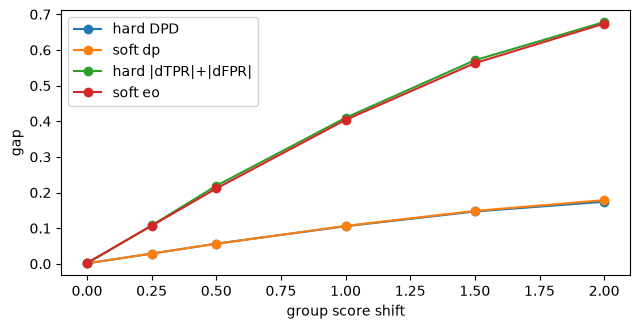

In [5]:
ax = fair_tbl[['hard DPD', 'soft dp', 'hard |dTPR|+|dFPR|', 'soft eo']].plot(marker='o', figsize=(6.5, 3.4))
ax.set_ylabel('gap'); plt.tight_layout(); plt.show()

## 4. Soft group ECE tracks hard ECE and is zero for calibrated scores

In [6]:
n = 200000; p = torch.rand(n, generator=g) * 0.9 + 0.05; yy = (torch.rand(n, generator=g) < p).float()
aa = (torch.rand(n, generator=g) < 0.5).long(); lg0 = torch.log(p / (1 - p)); rows = []
for shift in [0, 0.25, 0.5, 1.0, 2.0]:
    lg = lg0 + shift
    rows.append({'logit shift': shift, 'hard ECE': ece_equal_freq(yy.numpy(), torch.sigmoid(lg).numpy()),
                 'soft group ECE': soft_group_ece(lg, yy, aa).item()})
pd.DataFrame(rows).set_index('logit shift').round(4)

,hard ECE,soft group ECE
logit shift,,
0.00,0.0031,0.0019
0.25,0.0459,0.0459
0.50,0.0909,0.0909
1.00,0.1767,0.1767
2.00,0.3195,0.3195


## 5. All lambdas = 0: joint loss equals the A2 loss (real validation batch, real class weights)

In [7]:
val, cards = load_arrays(cfg, 'val')
ix = np.random.default_rng(0).choice(len(val.y), 2048, replace=False)
xc, xk = torch.from_numpy(val.cont[ix]), torch.from_numpy(val.cat[ix])
yb, ab = torch.from_numpy(val.y[ix]).float(), torch.from_numpy(val.a[ix]).long()
model = JointModel(build_model('tabtransformer', xc.shape[1], cards, cfg['model_defaults'], {})).eval()
logit, _, adv = model(xc, xk); a2 = weighted_bce(logit, yb, W['0'], W['1']); rows = []
for epoch in [0, 4, 20]:
    jt = JointLoss(JointConfig.from_config(cfg), W['0'], W['1']); jt.set_epoch(epoch)
    tot, parts = jt(logit, yb, ab, adv)
    rows.append({'epoch': epoch, 'A2 loss': a2.item(), 'joint loss (lambdas=0)': tot.item(), 'difference': (tot - a2).item(), 'terms computed': list(parts)})
pd.DataFrame(rows).set_index('epoch')

,A2 loss,joint loss (lambdas=0),difference,terms computed
epoch,,,,
0,0.689542,0.689542,0.0,[wce]
4,0.689542,0.689542,0.0,[wce]
20,0.689542,0.689542,0.0,[wce]


## 6. Adversary is inactive during warm-up, active afterwards

In [8]:
rows = []
for epoch in [1, 6, 20]:
    jt = JointLoss(JointConfig.from_config(cfg, lambda_f=1.0, lambda_c=1.0, lambda_a=1.0), W['0'], W['1'])
    jt.set_epoch(epoch); model.zero_grad(); logit, _, adv = model(xc, xk)
    tot, parts = jt(logit, yb, ab, adv); tot.backward()
    head = sum(float(p.grad.abs().sum()) for p in model.adversary.parameters() if p.grad is not None)
    rows.append({'epoch': epoch, 'effective lambda_a': jt.lambdas()['a'], 'terms computed': list(parts), 'adversary-head |grad| sum': head})
pd.DataFrame(rows).set_index('epoch')

,effective lambda_a,terms computed,adversary-head |grad| sum
epoch,,,
1,0.0,[wce],0.000000
6,0.6,"[wce, fair, cal, adv]",1.500516
20,1.0,"[wce, fair, cal, adv]",2.500860


## 7. A 200-row batch is memorised (wCE + fairness + calibration terms on)

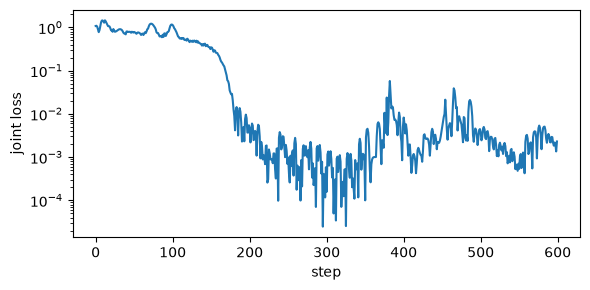

start 1.0784 -> end 0.00230


In [9]:
torch.manual_seed(0); r = np.random.default_rng(0); sub = r.choice(len(val.y), 200, replace=False)
xc2, xk2 = torch.from_numpy(val.cont[sub]), torch.from_numpy(val.cat[sub])
y2, a2_ = torch.from_numpy(val.y[sub]).float(), torch.from_numpy(val.a[sub]).long()
m2 = JointModel(build_model('mlp', xc2.shape[1], cards, cfg['model_defaults'], {'dropout': 0.0}))
jc7 = JointConfig.from_config(cfg, lambda_f=1.0, lambda_c=1.0, lambda_a=0.0); jc7.warmup_epochs = 0; jc7.ramp_epochs = 0
jt = JointLoss(jc7, W['0'], W['1'])
jt.set_epoch(0); opt = torch.optim.Adam(m2.parameters(), lr=5e-3); curve = []
for _ in range(600):
    opt.zero_grad(); lg, _, ad = m2(xc2, xk2); tot, parts = jt(lg, y2, a2_, ad); tot.backward(); opt.step(); curve.append(tot.item())
plt.figure(figsize=(6, 3)); plt.semilogy(curve); plt.xlabel('step'); plt.ylabel('joint loss'); plt.tight_layout(); plt.show()
print('start %.4f -> end %.5f' % (curve[0], curve[-1]))

## 8. Stage 4 unit tests (live run)

In [10]:
r = subprocess.run([sys.executable, '-m', 'pytest', 'tests/test_joint.py', '-q', '-p', 'no:warnings'],
                   cwd=ROOT, capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-1]); assert r.returncode == 0

21 passed in 6.30s


## What this shows

- **GRL** is an exact identity in the forward pass, and its backward pass multiplies the gradient by -lambda (error 0.0 for lambda = 0, 0.5, 1, 2). The adversary head applies the GRL with coefficient 1 and the strength lambda_a sits on the loss term, so with lambda_a = 0 the head cannot affect the trunk.
- **Warm-up and ramp.** All effective lambdas are 0 for the first 3 epochs, then rise linearly and reach their targets at epoch 8. During warm-up only the weighted-CE term is computed: the adversary head receives no gradient (|grad| = 0), while after the ramp it does.
- **Soft fairness loss** follows the hard metrics closely on synthetic data: the soft demographic-parity term matches the hard flag-rate gap to within 0.005 (for example 0.1485 vs 0.1468 at a group shift of 1.5), and the soft equalized-odds term (sum of the TPR and FPR gaps) matches the hard sum of gaps within about 0.01. It is about 0 when both groups are scored alike. Note that the reported hard EOD is the larger of the two gaps, while the soft term is their sum, so the surrogate is slightly stricter.
- **Soft group ECE** reproduces the hard ECE almost exactly (0.0459, 0.0909, 0.1767, 0.3195 for logit shifts 0.25 to 2) and is about 0.002 on perfectly calibrated data.
- **Lambda = 0 equals A2.** On a real validation batch with the real class weights the joint loss and the A2 loss are identical (difference exactly 0.0), at warm-up, mid-ramp and after the ramp; gradients are identical too (unit test).
- **A 200-row batch is memorised** (joint loss 1.08 to 0.002 with the fairness and calibration terms on).
- **Not tested yet (Phase 4):** the gender-head AUC trending toward 0.5 in a short joint run, adversary stability, and the stratified batch sampler. Nothing here shows that the joint objective improves the trade-off; that is what the Phase 5 sweep measures.
